# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) dilakukan untuk memahami struktur distribusi kelas tutupan lahan dan memverifikasi keterpisahan spektral (*spectral separability*) antar kelas sebelum tahap pemodelan klasifikasi. Sampel poligon Laut nomor 0 sampai 18 (`Laut_0000` hingga `Laut_0018`) dikecualikan terlebih dahulu karena posisinya berada di luar batas wilayah Provinsi Jawa Timur.

## 1. Distribusi Jumlah Piksel per Kelas

Diagram batang horizontal berikut menampilkan volume sampel piksel untuk setiap kategori tutupan lahan pada dataset valid.

C:\Users\hp\AppData\Local\Temp\ipykernel_15144\1627578237.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


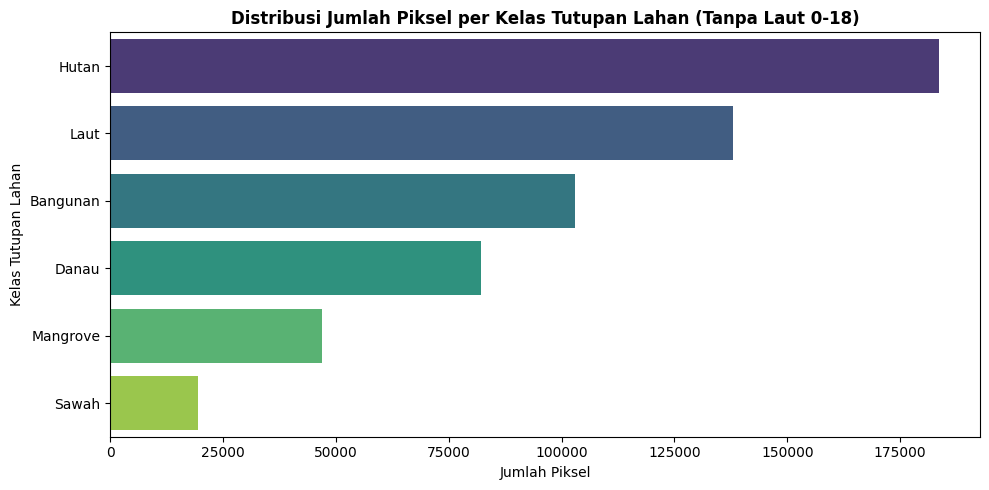

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

dataset_path = next(
    (
        candidate
        for folder in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            folder / "piksel_s2_JTM.csv",
            folder / "Tugas" / "UTS" / "piksel_s2_JTM.csv",
        )
        if candidate.is_file()
    ),
    None,
)
if dataset_path is None:
    raise FileNotFoundError("Dataset piksel_s2_JTM.csv tidak ditemukan.")

df = pd.read_csv(dataset_path)

# Hapus sampel poligon laut 0 sampai 18 karena melebihi batas Jawa Timur
excluded_laut = {f"Laut_{index:04d}" for index in range(19)}
df = df[~df["poligon_id"].isin(excluded_laut)].copy()

plt.figure(figsize=(10, 5))
sns.countplot(
    y='label_teks',
    data=df,
    palette='viridis',
    order=df['label_teks'].value_counts().index
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan (Tanpa Laut 0-18)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel', fontsize=10)
plt.ylabel('Kelas Tutupan Lahan', fontsize=10)
plt.tight_layout()
plt.show()

### Interpretasi Distribusi:
- **Hutan (183.509 piksel)** dan **Laut (138.000 piksel)** memiliki volume sampel terbesar karena tutupan vegetasi hutan lindung/pegunungan dan perairan laut regional Jawa Timur.
- **Bangunan (103.017 piksel)** dan **Danau (82.245 piksel)** memiliki representasi yang kuat di kawasan perkotaan dan perairan darat.
- **Mangrove (46.985 piksel)** dan **Sawah (19.512 piksel)** memiliki volume yang lebih terkonsentrasi namun mencukupi untuk pelatihan model terstratifikasi.

---

## 2. Distribusi Nilai NDVI per Kelas Tutupan Lahan

Indeks vegetasi *Normalized Difference Vegetation Index* (NDVI) dianalisis untuk melihat bagaimana pantulan inframerah dekat (NIR) dan serapan merah (Red) membedakan kelas vegetasi dari non-vegetasi.

C:\Users\hp\AppData\Local\Temp\ipykernel_15144\1096271146.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')


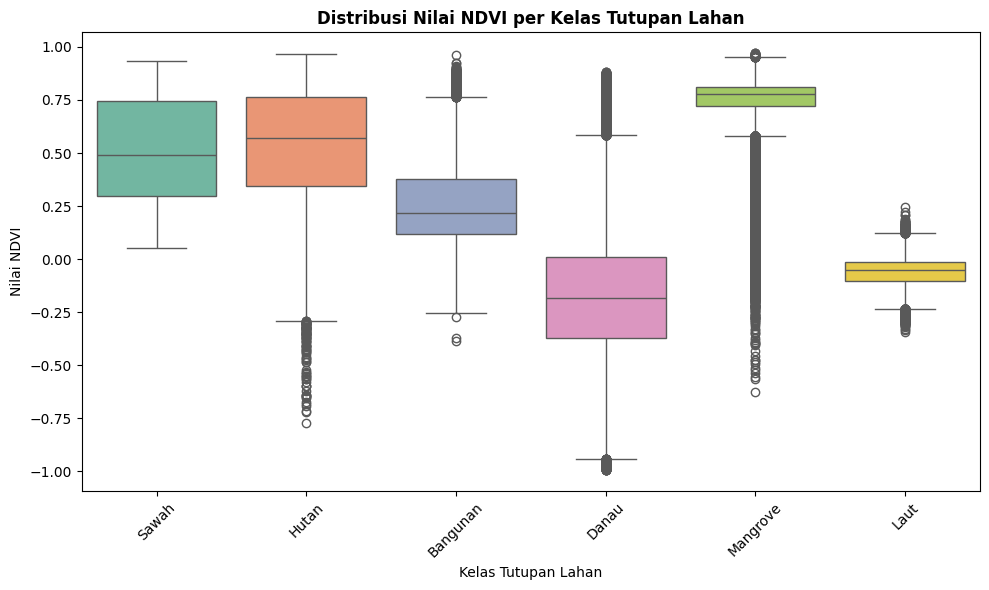

In [2]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Kelas Tutupan Lahan', fontsize=10)
plt.ylabel('Nilai NDVI', fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretasi Karakteristik Spektral NDVI:
1. **Vegetasi Rapat (Hutan & Mangrove)**: Memiliki nilai median NDVI tertinggi ($> 0.65$), mencerminkan kanopi hijau yang sangat aktif menyerap cahaya merah dan memantulkan inframerah dekat.
2. **Pertanian (Sawah)**: Menunjukkan rentang variasi NDVI yang cukup lebar ($0.25 - 0.75$). Hal ini wajar dalam studi spasial pertanian karena sampel sawah mencakup fase bera (tanah basah/kering), genangan air tanam, hingga fase vegetatif hijau tua sebelum panen.
3. **Badan Air (Danau & Laut)**: Memiliki nilai NDVI negatif atau mendekati 0, karena air menyerap hampir seluruh gelombang inframerah dekat (NIR).
4. **Wilayah Terbangun (Bangunan)**: Memiliki nilai NDVI rendah ($0.05 - 0.25$), membedakannya secara jelas dari kelompok vegetasi hijau.